# Mida coherencia de frentes y ancho mínimo

**Pregunta:** ¿Cómo fragmenta un plan CPIT factible un banco y qué cambia al suavizar tramos estrechos?

**Nivel:** 1 — Fundamentos

**Prerrequisitos:** Complete el tema 01, planificación CPIT y cotas.

**Tiempo de lectura:** 18 minutes

## Objetivos

Un plan por bloques puede respetar precedencias y capacidad mientras dispersa la extracción en frentes desconectados. Este notebook mide esa forma operacional en vez de considerar el NPV como único resultado. Construye un caso sintético 3D, lo resuelve, calcula componentes con conectividad de seis vecinos y anchos de tramos de banco, y luego llama al suavizador de ancho de OreBlocks. El suavizador puede mover un tramo estrecho hacia el período elegido por sus vecinos del banco, pero solo acepta movimientos que preservan precedencia y dejan espacio en todos los recursos receptores. Es un postproceso, no un optimizador con ancho mínimo. La geometría didáctica es pequeña y el ancho se mide en bloques, no en metros. El plan no es diseño minero ni aprobación geotécnica.

## Preparación

Desde la raíz del repositorio, instale el entorno fijado con `python -m pip install -r notebooks/requirements.txt`. `oreblocks==0.6.3`.

```bash
python -m pip install -r notebooks/requirements.txt
```

In [1]:
# Cargue la canalización de instancias y los métodos geométricos de OreBlocks.
import importlib.metadata as metadata
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
print('oreblocks', metadata.version('oreblocks'))

oreblocks 0.6.3


## Datos

La entrada declarada la genera la canalización MIT de PhaseFlow: gemelo sintético porfídico, dimensiones 8×8×4, semilla fija 41, seis períodos y dos límites de recursos. La canalización entrega coordenadas, precedencias, ley y tonelaje. OreBlocks 0.6.3 calcula el plan, las métricas de coherencia y el suavizado. No se usa un modelo de bloques MineLib publicado. El ancho objetivo está en bloques de grilla porque este caso no declara dimensiones topográficas; no lo convierta a metros sin tamaño de celda declarado. Bai et al. discuten unos 100 m como objetivo en otro modelo de diseño de pushbacks. Ese número es contexto y no el objetivo de este plan sintético.

## Método

Para cada período t, la coherencia cuenta componentes conectados con seis vecinos entre los bloques asignados a t. El ancho de banco es el mínimo tramo consecutivo extraído en cualquiera de los dos ejes horizontales. Son indicadores de fragmentación, no restricciones operacionales completas. `enforce_min_width` considera bloques extraídos cuyo tramo es menor que el objetivo, vota entre cuatro vecinos del mismo banco por un período receptor y acepta el movimiento solo si se mantienen precedencias en ambas direcciones y factibilidad de todos los recursos receptores. Repite un número acotado de pasadas. El informe incluye cantidades estrechas antes y después, bloques movidos, rechazos por capacidad, NPV y ancho mínimo. La entrada debe ser factible antes de la llamada. El resultado factible aún requiere revisión operacional: estos indicadores no modelan caminos, taludes ni acceso.

### Paso 1: construya el caso

La canalización construye y valida una instancia didáctica de 256 bloques. Las coordenadas definen adyacencia y el grafo de precedencias restringe el orden. Lea los dos límites de recursos como parte del caso: si un movimiento cabe en extracción pero excede procesamiento, debe rechazarse. El código informa dimensiones y aceptación para que las mediciones posteriores tengan una entrada conocida.

In [2]:
# Genere con PhaseFlow un caso sintético con semilla.
case = Case(
    id='operability-porphyry-8x8x4', category='teaching',
    title_en='Porphyry coherence lesson', title_es='Leccion de coherencia porfídica',
    deposit=DepositSpec(kind='twin', archetype='porphyry', dims=(8, 8, 4), seed=41),
    scenario=Scenario(periods=6, discount_rate=0.08,
        capacity_fraction=(0.85, 0.55), resource_names=('mining', 'processing')),
)
instance = build_instance(case)
print('contrato aceptado:', instance.report.ok, '| bloques:', instance.n_blocks)

contrato aceptado: True | bloques: 256


### Paso 2: calcule el plan factible

La heurística Expected construye un plan bajo las restricciones CPIT declaradas. Conservamos asignaciones temporales y NPV como referencia. Un plan factible y valioso aún puede dividir un banco en varios componentes desconectados; valor y coherencia geométrica responden preguntas distintas. Medimos el plan original antes de modificarlo, sin depender de un artefacto guardado ni de una gráfica copiada del bake del producto.

In [3]:
# Calcule un plan CPIT determinista y conserve sus asignaciones temporales.
schedule, _ = ob.solve_cpit(instance.cpit, instance.precedence, method='expected', local_search=False)
print(schedule.method, '| VPN:', round(schedule.npv, 2), '| extraidos:', schedule.mined_blocks)

toposort:expected[r1] | VPN: 6241283.54 | extraidos: 113


### Paso 3: mida y suavice

`schedule_coherence` devuelve componentes por período, tamaño del componente mayor y ancho mínimo de banco. `enforce_min_width` devuelve luego un plan nuevo y un informe. Las cantidades antes y después hacen visible el mecanismo: algunos tramos se mueven y los que no tienen capacidad receptora permanecen. Como el método valida precedencias y espacio durante cada movimiento, la diferencia de NPV refleja un postproceso factible bajo estas restricciones y no un exceso de capacidad. No inserta bloques ni altera el pit final.

In [4]:
# Mida la coherencia del plan base por período.
before = ob.schedule_coherence(
    schedule.period_of_block, instance.x, instance.y,
    instance.level, instance.cpit.n_periods,
)
print([(row.period, row.components, row.min_width_blocks) for row in before])

[(0, 1, 1), (1, 4, 1), (2, 5, 1), (3, 8, 1), (4, 6, 1), (5, 3, 1)]


Aplique ahora el postproceso del paquete con ancho objetivo tres. Devuelve un plan nuevo y un informe; mida otra vez la coherencia de las asignaciones devueltas.

In [5]:
# Suavice tramos estrechos y mida la coherencia del plan devuelto.
smoothed, report = ob.enforce_min_width(
    instance.cpit, schedule, instance.x, instance.y, instance.level,
    instance.precedence, target_width=3,
)
after = ob.schedule_coherence(
    smoothed.period_of_block, instance.x, instance.y,
    instance.level, instance.cpit.n_periods,
)
print('movidos:', report.moved_blocks, '| rechazos por capacidad:', report.blocked_by_capacity)
print('bloques estrechos:', report.below_target_before, 'a', report.below_target_after)
print('VPN:', round(report.npv_before, 2), 'a', round(report.npv_after, 2))

movidos: 25 | rechazos por capacidad: 29
bloques estrechos: 90 a 89
VPN: 6241283.54 a 6245690.97


Grafique las cantidades de tramos estrechos antes y después. Interprete junto con movimientos y rechazos; es un indicador de grilla, no garantía de ancho físico.

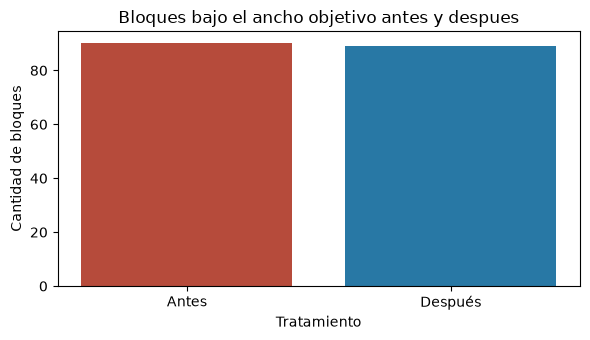

In [6]:
# Grafique bloques bajo el ancho objetivo antes y después del suavizado.
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(['Antes', 'Después'], [report.below_target_before, report.below_target_after], color=['#b64b3b', '#2878a5'])
ax.set(title='Bloques bajo el ancho objetivo antes y despues', xlabel='Tratamiento', ylabel='Cantidad de bloques')
fig.tight_layout()
plt.show()

### Figura 1

Grafique la cantidad calculada de bloques extraídos en tramos menores que tres bloques antes y después del suavizado. Una reducción indica que se absorbieron tramos elegibles; el valor puede permanecer igual por geometría aislada o movimientos bloqueados. El gráfico no muestra accesos, fases, radio de giro ni riesgo geotécnico. La unidad es cantidad de bloques en esta grilla declarada. Compare cantidades movidas y rechazadas por capacidad para entender por qué cambió el indicador.

El informe geométrico no certifica precedencia ni factibilidad de recursos; estos controles revisan el plan devuelto.

In [7]:
# Confirmar que el postproceso de ancho conserva los invariantes de planificación.
postprocess_controls = ob.run_controls(instance.cpit, instance.precedence, smoothed)
print('controles del postproceso aprobados:', postprocess_controls.all_pass)


controles del postproceso aprobados: True


## Resultados

**Respuesta:** El ajuste de ancho 3 movió 25 bloques, rechazó 29 movimientos por capacidad y redujo los bloques bajo el ancho objetivo de 90 a 89. El NPV subió de 6241283.54 a 6245690.97, una ganancia de 4407.43 unidades de valor. Este resultado sintético no demuestra operabilidad física.

In [8]:
# Imprima las cantidades calculadas en el informe de suavizado.
print(f'movidos={report.moved_blocks}; rechazados={report.blocked_by_capacity}')
print(f'bloques_estrechos={report.below_target_before}->{report.below_target_after}')
print(f'cambio_vpn={report.npv_after-report.npv_before:.2f}')

movidos=25; rechazados=29
bloques_estrechos=90->89
cambio_vpn=4407.43


## Resumen

Midió la forma del plan antes y después de ejecutar el suavizador de ancho del paquete. Preserva precedencias y capacidad modeladas, pero solo mueve bloques con un período receptor factible. Interprete el ancho en bloques y los indicadores geométricos como evidencia para revisión, no como modelo operacional completo. Un diseño real requiere dimensiones topográficas, accesos y caminos, revisión geotécnica y posiblemente variables de ancho dentro de la optimización en vez de un postproceso.

## Referencias

- OreBlocks 0.6.3: `oreblocks.schedule_coherence`, `oreblocks.enforce_min_width`.
- Chicoisne et al. (2012), multi-period open-pit planning: https://doi.org/10.1287/opre.1120.1050.
- Bai et al. (2018), minimum mining width and pushback design: https://doi.org/10.17159/2411-9717/2018/v118n5a8.
- PhaseFlow method evidence: `docs/methodologies/10_operability.md`.